# TP4 - Redes convolucionales para clasificar lesiones de piel (ISIC)

**Dataset:** imágenes dermatoscópicas ISIC de 9 clases (~880 imágenes en la carpeta `data/Split_smol`, con una subcarpeta por clase dentro de `train/` y `val/`).

El **código ya está resuelto y probado**. Lo que se evalúa es **su análisis**. El cómputo lleva unos 15-20 minutos (medido en una CPU de 20 núcleos), y les queda la mayor parte de las 2 horas para interpretar resultados.

**Qué se trabaja en este TP:** análisis exploratorio, limpieza de duplicados y split, convoluciones, pooling y campo receptivo, comparación MLP vs. CNN, decisiones de arquitectura, resolución de entrada, data augmentation y evaluación final.
**Qué NO se repite** porque ya lo hicieron en los TP1 a TP3: búsqueda de hiperparámetros con Optuna, dropout/L2/BatchNorm como variables de estudio (la BatchNorm queda fija dentro del bloque convolucional), inicialización y logging con TensorBoard/MLflow.

**Cómo trabajar:** ejecuten de arriba hacia abajo, lean los outputs y completen las celdas **✏️** (observaciones de EDA, explicación del código convolucional y cuatro análisis). Las comparaciones usan **3 semillas** y reportan media ± desvío: una diferencia solo cuenta si supera ese ruido.

**Reglas metodológicas (las mismas de los TPs anteriores):**
- Las entradas van **normalizadas** (media y desvío por canal calculados **solo en train**).
- El **test se usa una sola vez**, en la sección 8. Todo lo demás se decide con validación.
- La augmentation se aplica **solo a train y después del split**.
- Las conclusiones tienen que **coincidir con los outputs** de su corrida.

## 0. Configuración
Si no tienen GPU, los valores por defecto funcionan en CPU. Si cambian alguna constante, **anótenlo en su análisis**.

In [1]:
import os, time, random, copy, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import warnings; warnings.filterwarnings("ignore")

DATA_DIR    = "data/Split_smol"    # carpeta con train/ y val/ (una subcarpeta por clase)
SIZES       = [32, 64, 96]         # resoluciones de entrada que se van a comparar
SEEDS       = [0, 1, 2]            # semillas para medir ruido
MAX_EPOCHS  = 60                   # épocas máximas (con early stopping)
PATIENCE    = 10                   # épocas sin mejorar val_loss antes de cortar
BATCH       = 32
AUG_COPIES  = 2                    # copias aumentadas que se agregan a cada imagen de train
SEED_SPLIT  = 42                   # semilla del split (NO cambiarla entre corridas)
SEEDS_FINAL = [0, 1, 2, 3, 4]      # semillas de la evaluación final

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
print("Dispositivo:", device, "| torch", torch.__version__)

Dispositivo: cuda | torch 2.14.1+cu130


## 1. Análisis exploratorio (EDA)
Antes de modelar hay que mirar los datos: cuántas imágenes hay por clase, de qué tamaños son, cómo se ven y si hay algo raro (desbalance, resoluciones distintas por clase, **imágenes repetidas**). Acá todavía no se divide nada: se trabaja con todas las imágenes tal como vienen.

In [3]:
class_names = sorted(os.listdir(f"{DATA_DIR}/train")); NUM_CLASSES = len(class_names)
meta = []
for sp in ["train", "val"]:
    for ci, c in enumerate(class_names):
        for f in sorted(os.listdir(f"{DATA_DIR}/{sp}/{c}")):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                p = f"{DATA_DIR}/{sp}/{c}/{f}"
                with Image.open(p) as im: w, h = im.size
                meta.append(dict(path=p, carpeta=sp, clase=c, y=ci, w=w, h=h, md5=hashlib.md5(open(p, "rb").read()).hexdigest()))
df = pd.DataFrame(meta); df["res"] = df["w"].astype(str) + "x" + df["h"].astype(str); df["aspecto"] = df["w"] / df["h"]
print(f"{len(df)} imágenes, {NUM_CLASSES} clases")

# Se cargan todas las imágenes una sola vez, ya redimensionadas a cuadrados, para todas las resoluciones
t0 = time.time(); RAW = {s: [] for s in SIZES}
for p in df["path"]:
    with Image.open(p) as im0:
        im = im0.convert("RGB")
        for s in SIZES: RAW[s].append(np.asarray(im.resize((s, s), Image.BILINEAR)))
X_U8 = {s: torch.from_numpy(np.stack(RAW[s])).permute(0, 3, 1, 2).contiguous() for s in SIZES}; del RAW
Y = torch.from_numpy(df["y"].values); labels = df["y"].values
print(f"Carga de imágenes: {time.time() - t0:.0f}s | tensor {tuple(X_U8[64].shape)} uint8")

878 imágenes, 9 clases
Carga de imágenes: 10s | tensor (878, 3, 64, 64) uint8


carpeta,train,val,All
clase,,,
Actinic keratosis,80,20,100
Atopic Dermatitis,81,21,102
Benign keratosis,80,20,100
Dermatofibroma,80,20,100
Melanocytic nevus,80,20,100
Melanoma,80,20,100
Squamous cell carcinoma,80,20,100
Tinea Ringworm Candidiasis,56,20,76
Vascular lesion,80,20,100


Resoluciones más frecuentes:


res,600x450,1024x768,294x222,1024x764,1022x767,767x576,919x802,1024x681
imágenes,400,135,102,74,21,12,6,5


Fracción de cada clase por resolución:


res,1022x767,1024x764,1024x768,294x222,600x450,otras
clase,,,,,,
Actinic keratosis,0.00,0.00,0.00,0.0,1.0,0.00
Atopic Dermatitis,0.00,0.00,0.00,1.0,0.0,0.00
Benign keratosis,0.00,0.74,0.00,0.0,0.0,0.26
Dermatofibroma,0.00,0.00,0.00,0.0,1.0,0.00
Melanocytic nevus,0.18,0.00,0.79,0.0,0.0,0.03
Melanoma,0.03,0.00,0.56,0.0,0.0,0.41
Squamous cell carcinoma,0.00,0.00,0.00,0.0,1.0,0.00
Tinea Ringworm Candidiasis,0.00,0.00,0.00,0.0,0.0,1.00
Vascular lesion,0.00,0.00,0.00,0.0,1.0,0.00


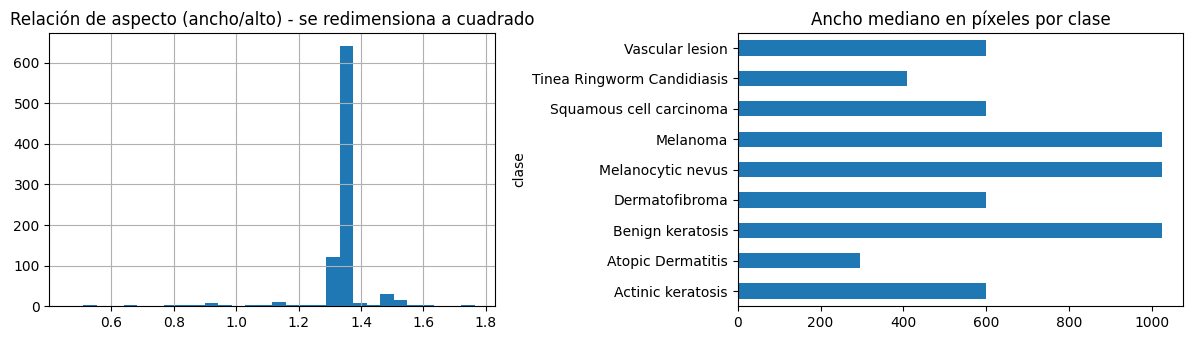

In [4]:
# 1.1 Clases y carpeta de origen
display(pd.crosstab(df["clase"], df["carpeta"], margins=True))
# 1.2 Resoluciones: ¿son todas iguales? ¿dependen de la clase?
print("Resoluciones más frecuentes:"); display(df["res"].value_counts().head(8).to_frame("imágenes").T)
top = df["res"].value_counts().head(5).index
ct = pd.crosstab(df["clase"], df["res"].where(df["res"].isin(top), "otras"), normalize="index").round(2)
print("Fracción de cada clase por resolución:"); display(ct)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df["aspecto"].hist(bins=30, ax=ax[0]); ax[0].set_title("Relación de aspecto (ancho/alto) - se redimensiona a cuadrado")
(df.groupby("clase")["w"].median()).plot.barh(ax=ax[1]); ax[1].set_title("Ancho mediano en píxeles por clase"); plt.tight_layout(); plt.show()

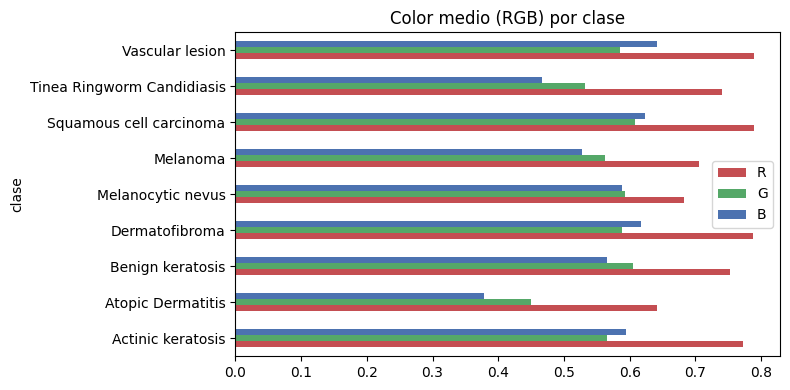

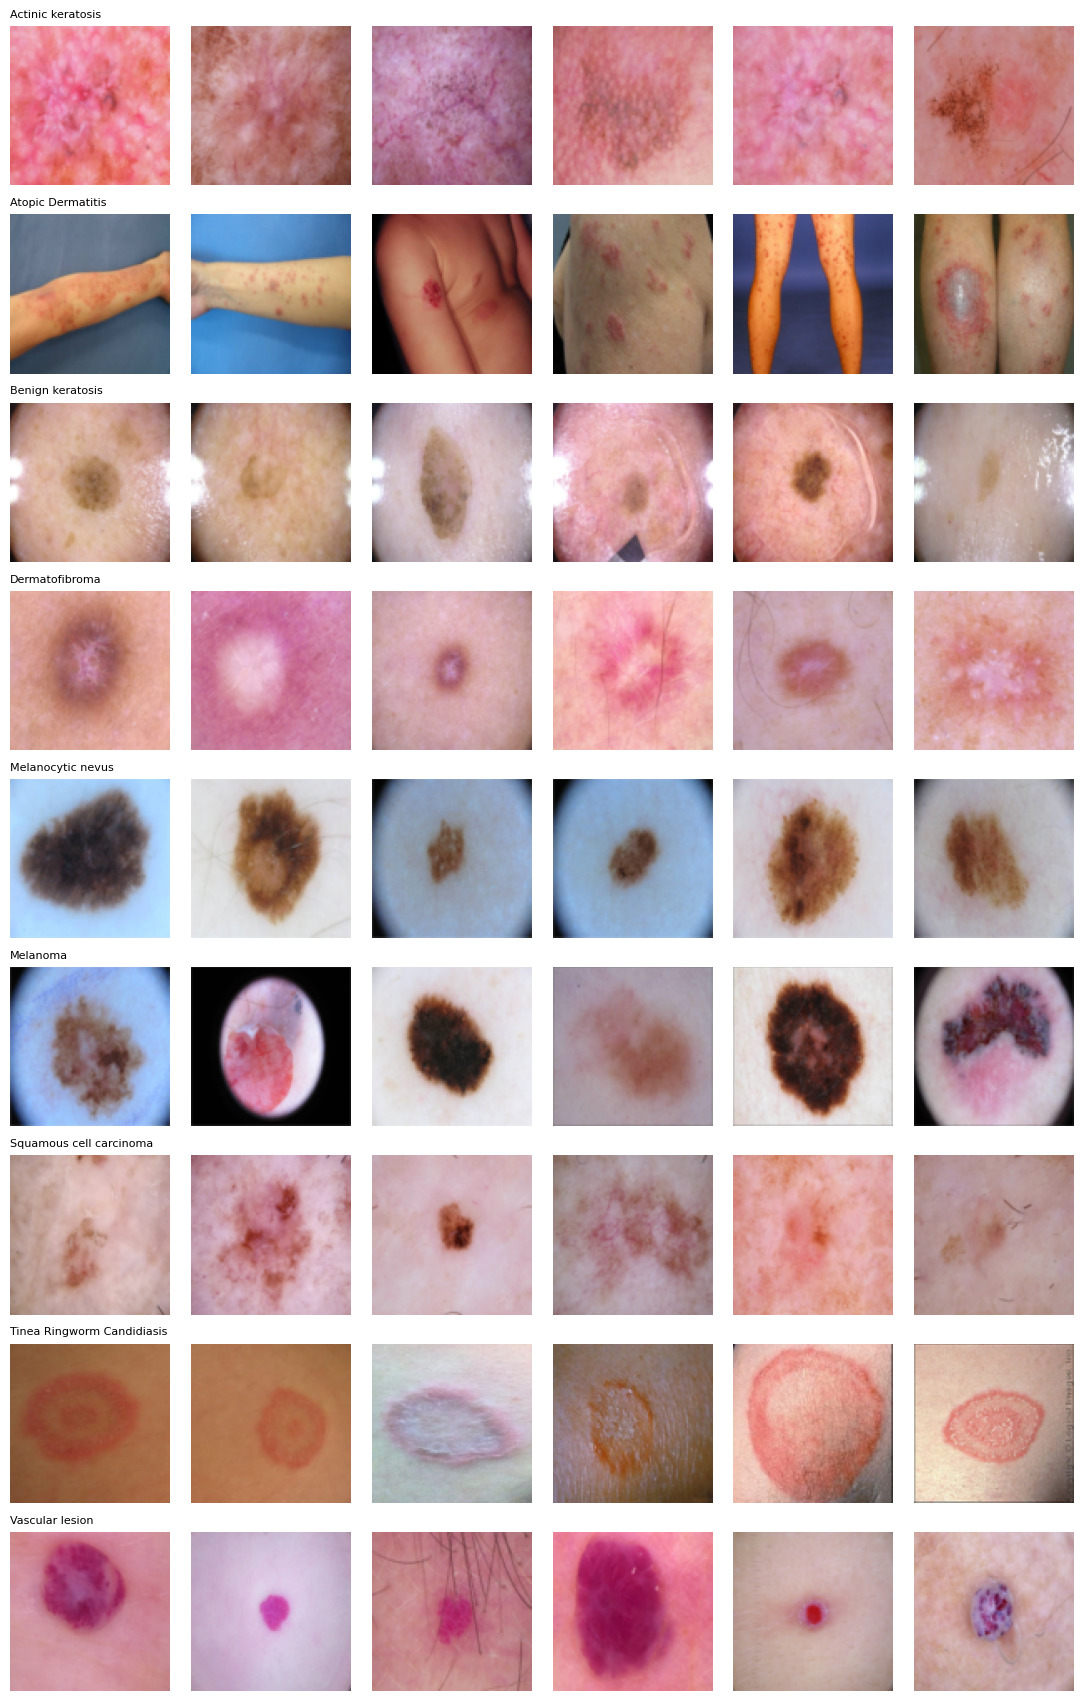

In [5]:
# 1.3 Color medio por clase y ejemplos
mean_rgb = pd.DataFrame(X_U8[32].float().mean((2, 3)).numpy() / 255, columns=["R", "G", "B"]); mean_rgb["clase"] = df["clase"].values
mean_rgb.groupby("clase").mean().plot.barh(color=["#c44e52", "#55a868", "#4c72b0"], figsize=(8, 4), title="Color medio (RGB) por clase"); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(11, 1.9 * NUM_CLASSES))
for ci in range(NUM_CLASSES):
    ids = np.where(labels == ci)[0][:6]
    for j, i in enumerate(ids): axes[ci, j].imshow(X_U8[96][i].permute(1, 2, 0)); axes[ci, j].axis("off")
    axes[ci, 0].set_title(class_names[ci], fontsize=8, loc="left")
plt.tight_layout(); plt.show()

### 1.4 Imágenes duplicadas
El dataset viene con una partición `train/`/`val/` propia. Si una misma imagen está en las dos carpetas, la validación **no mide generalización** (el modelo ya vio esas imágenes). Se buscan duplicados **exactos** (mismo hash MD5 del archivo) y se verifica con un hash perceptual (diferencias entre píxeles vecinos de una miniatura) que no queden **casi-duplicados** (recortes o recompresiones).

In [6]:
g = df.groupby("md5")
dup_groups = [idx for _, idx in g.groups.items() if len(idx) > 1]
cross = [idx for idx in dup_groups if df.loc[idx, "carpeta"].nunique() > 1]
print(f"Grupos de imágenes idénticas: {len(dup_groups)} (de los cuales {len(cross)} están repetidos entre train y val)")
print("Por clase:", df.loc[[idx[0] for idx in dup_groups], "clase"].value_counts().to_dict())
print("Conflictos de etiqueta (misma imagen con clases distintas):", sum(df.loc[idx, "y"].nunique() > 1 for idx in dup_groups))

# hash perceptual: miniatura gris 16x17, bit = pixel > vecino derecho (256 bits); distancia de Hamming
gray = X_U8[32].float().mean(1, keepdim=True)
th_ = F.interpolate(gray, size=(16, 17), mode="area")
H = (th_[..., 1:] > th_[..., :-1]).flatten(1).numpy()
near = []
for i in range(len(H)):
    d = (H[i] != H[i + 1:]).sum(1)
    near += [(i, i + 1 + j) for j in np.where(d <= 8)[0]]
near_not_exact = [(i, j) for i, j in near if df.loc[i, "md5"] != df.loc[j, "md5"]]
print(f"Pares con hash perceptual casi igual (<=8 bits de 256): {len(near)} | de ellos NO idénticos por MD5: {len(near_not_exact)}")

Grupos de imágenes idénticas: 34 (de los cuales 33 están repetidos entre train y val)
Por clase: {'Atopic Dermatitis': 22, 'Tinea Ringworm Candidiasis': 12}
Conflictos de etiqueta (misma imagen con clases distintas): 0
Pares con hash perceptual casi igual (<=8 bits de 256): 34 | de ellos NO idénticos por MD5: 0


### ✏️ TUS OBSERVACIONES DEL EDA
Respondan en pocas líneas, con los números de los outputs de arriba:
1. ¿Qué tan desbalanceado está el dataset? ¿Qué cambia respecto de la partición original `train`/`val`?
2. ¿Hay clases que se distinguen por resolución, relación de aspecto o color de fondo? ¿Qué riesgo tiene eso para un modelo que ve las imágenes redimensionadas?
3. ¿Qué duplicados encontraron, en qué clases y por qué importan para la validación? ¿Qué hubiera pasado con la `val_acc` si no los eliminaran?

#Respuestas:
1) El dataset original tiene 878 imágenes en 9 clases (697 en train y 181 en val) y está bastante balanceado: 7 clases tienen 100 imágenes (80/20), Atopic Dermatitis tiene 102 (81/21) y la más chica es Tinea Ringworm Candidiasis con 76 (56/20). El problema de la partición original es que no traía conjunto de test y tenía fotos repetidas entre carpetas. Al borrar los 34 duplicados quedan 844 imágenes únicas, que se vuelven a dividir estratificadas en 60/20/20 (506 train, 169 val, 169 test): ahí Atopic Dermatitis baja a 80 (48/16/16), Tinea Ringworm Candidiasis a 64 (38/13/13), y las otras 7 quedan en 80 (60/20/20).

2) Sí, hay clases marcadas por el formato de origen. Atopic Dermatitis es 100% de 294x222, cuatro clases (Actinic keratosis, Dermatofibroma, Squamous cell carcinoma y Vascular lesion) son 100% de 600x450, y Melanocytic nevus (79%) junto con Melanoma (56%) vienen casi siempre en 1024x768. Además, casi todas tienen relación de aspecto cercana a 1.33 (4:3), así que al pasarlas a cuadrado se achatan un poco a lo ancho. En color y fondo también se nota diferencia: Atopic Dermatitis tiene valores RGB más bajos (R=0.65, G=0.45, B=0.38) porque son fotos clínicas de brazos, piernas o torso con fondos variados, mientras que Melanoma y Melanocytic nevus cuentan con imagenes tomadas de microscopios donde aparecen las esquinas negras. El riesgo es que el modelo agarre "atajos", como el suavizado distinto al reescalar desde 294x222 frente a 1024x768, la deformación o los bordes negros en lugar de mirar la lesión en sí.

3) Se encontraron 34 grupos de imágenes idénticas por MD5 (22 en Atopic Dermatitis y 12 en Tinea Ringworm Candidiasis), sin conflictos de etiqueta, De esos 34 grupos, 33 estaban repetidos entre train y val. Si no se sacaban, el modelo habría memorizado esas fotos al entrenar y después las habría vuelto a evaluar en validación ( más del 18% de las imagenes en val, eran copias exactas de train, incluyendo casi toda la validación de Atopic Dermatitis). Eso hubiese inflado artificialmente la val_acc y ocultado el overfitting.

## 2. Eliminación de duplicados y split estratificado
- Se **elimina una copia de cada imagen duplicada** (se conserva una sola por grupo de MD5).
- Se juntan **todas** las imágenes que quedan (la partición original no sirve: tenía repetidas y no tenía test) y se hace un split **estratificado 60/20/20** con semilla fija. El test no se toca hasta la sección 8.
- Se calcula la **normalización** (media y desvío por canal) **solo con train**.

In [7]:
keep = df.groupby("md5").head(1).index.values            # una imagen por hash
print(f"Imágenes totales: {len(df)} -> sin duplicados: {len(keep)} (se eliminaron {len(df) - len(keep)})")
idx_tr, idx_tmp = train_test_split(keep, test_size=0.4, stratify=labels[keep], random_state=SEED_SPLIT)
idx_va, idx_te  = train_test_split(idx_tmp, test_size=0.5, stratify=labels[idx_tmp], random_state=SEED_SPLIT)
print(f"train {len(idx_tr)} | val {len(idx_va)} | test {len(idx_te)}")
print(pd.DataFrame({"train": pd.Series(df.loc[idx_tr, "clase"]).value_counts(), "val": pd.Series(df.loc[idx_va, "clase"]).value_counts(),
                    "test": pd.Series(df.loc[idx_te, "clase"]).value_counts()}).to_string())
assert not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_va, "md5"])) and not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_te, "md5"])) and not (set(df.loc[idx_va, "md5"]) & set(df.loc[idx_te, "md5"]))
STATS = {}
for s in SIZES:
    xt = X_U8[s][idx_tr].float() / 255
    STATS[s] = (xt.mean((0, 2, 3)).view(1, 3, 1, 1), xt.std((0, 2, 3)).view(1, 3, 1, 1))
print("mean/std por canal (64px, solo train):", STATS[64][0].flatten().numpy().round(3), STATS[64][1].flatten().numpy().round(3))

Imágenes totales: 878 -> sin duplicados: 844 (se eliminaron 34)
train 506 | val 169 | test 169
                            train  val  test
clase                                       
Actinic keratosis              60   20    20
Atopic Dermatitis              48   16    16
Benign keratosis               60   20    20
Dermatofibroma                 60   20    20
Melanocytic nevus              60   20    20
Melanoma                       60   20    20
Squamous cell carcinoma        60   20    20
Tinea Ringworm Candidiasis     38   13    13
Vascular lesion                60   20    20
mean/std por canal (64px, solo train): [0.743 0.572 0.565] [0.162 0.164 0.186]


## 3. Data augmentation a mano (solo sobre train, después del split)
No se usa ninguna librería de augmentation: las transformaciones están escritas con operaciones de tensores. Cada imagen de **train** se complementa con `AUG_COPIES` copias transformadas **ya generadas** (se calculan una vez, después del split, así que ninguna copia de una imagen de val/test puede filtrarse a train). Val y test **nunca** se aumentan.

Transformaciones disponibles: flips horizontal/vertical, rotaciones de 90° y brillo/contraste aleatorios. Las lesiones dermatoscópicas no tienen orientación privilegiada, pero el **color** es información diagnóstica.

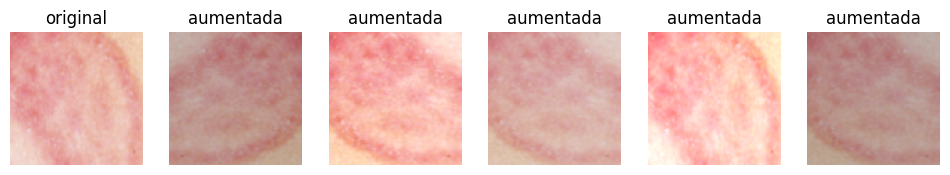

In [8]:
AUGS = {"ninguna": {}, "flips": dict(hflip=True, vflip=True),
        "flips+rot90": dict(hflip=True, vflip=True, rot90=True),
        "flips+rot90+color": dict(hflip=True, vflip=True, rot90=True, color=0.2)}

def augment(x, a):
    # x: tensor float [B,3,H,W] en [0,1]. Cada imagen recibe sus propias transformaciones al azar.
    B = x.shape[0]; x = x.clone()
    if a.get("hflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(3)
    if a.get("vflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(2)
    if a.get("rot90"):
        k = torch.randint(0, 4, (B,))
        for kv in (1, 2, 3):
            m = k == kv
            if m.any(): x[m] = torch.rot90(x[m], kv, (2, 3))
    if a.get("color"):
        c = a["color"]
        bri = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c; con = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c
        mu = x.mean((1, 2, 3), keepdim=True); x = ((x - mu) * con + mu) * bri
    return x.clamp(0, 1)

TRAIN_SETS = {}
def train_set(size, aug_name):
    # originales de train + AUG_COPIES copias aumentadas de cada una (generadas una vez, con semilla fija)
    key = (size, aug_name)
    if key not in TRAIN_SETS:
        x0, y0 = X_U8[size][idx_tr], Y[idx_tr]
        if aug_name == "ninguna": TRAIN_SETS[key] = (x0, y0)
        else:
            set_seed(1234); xs, ys = [x0], [y0]
            for _ in range(AUG_COPIES): xs.append((augment(x0.float() / 255, AUGS[aug_name]) * 255).round().to(torch.uint8)); ys.append(y0)
            TRAIN_SETS[key] = (torch.cat(xs), torch.cat(ys))
    return TRAIN_SETS[key]

# Vista de una imagen y sus versiones aumentadas
i0 = idx_tr[0]; base = X_U8[96][i0:i0 + 1].float() / 255; set_seed(3)
fig, ax = plt.subplots(1, 6, figsize=(12, 2.3)); ax[0].imshow(base[0].permute(1, 2, 0)); ax[0].set_title("original")
for k in range(1, 6): ax[k].imshow(augment(base, AUGS["flips+rot90+color"])[0].permute(1, 2, 0)); ax[k].set_title("aumentada")
for a in ax: a.axis("off")
plt.show()

## 4. Modelos y entrenamiento
- **`MLP`**: la referencia (Flatten + 2 capas ocultas).
- **`CNN`**: `n_blocks` bloques `Conv2d → BatchNorm → ReLU → MaxPool(2)` con `filters·2^b` canales, y una cabeza `Flatten → Linear(128) → ReLU → Dropout → Linear(clases)`.
- **`rf_full(...)`** calcula el **campo receptivo** teórico de la última capa convolucional.
- **Entrenamiento**: Adam, early stopping sobre `val_loss` restaurando el mejor estado, tiempo por época medido.

In [9]:
class MLP(nn.Module):
    def __init__(self, size, num_classes=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(3 * size * size, 512), nn.ReLU(),
                                 nn.Linear(512, 128), nn.ReLU(), nn.Linear(128, num_classes))
    def forward(self, x): return self.net(x)

class CNN(nn.Module):
    def __init__(self, size, n_blocks=3, filters=16, kernel=3, use_bn=True, dropout=0.2, num_classes=NUM_CLASSES):
        super().__init__()
        layers, cin = [], 3
        for b in range(n_blocks):
            cout = filters * 2 ** b
            layers += [nn.Conv2d(cin, cout, kernel, padding=kernel // 2, bias=not use_bn)]
            if use_bn: layers += [nn.BatchNorm2d(cout)]
            layers += [nn.ReLU(), nn.MaxPool2d(2)]
            cin = cout
        self.features = nn.Sequential(*layers)
        fs = size // 2 ** n_blocks                       # lado del mapa de activación después de los n_blocks pooling
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(cin * fs * fs, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, num_classes))
    def forward(self, x): return self.head(self.features(x))

def rf_full(n_blocks, kernel):
    # campo receptivo de la última conv: cada conv suma (k-1)*salto; cada maxpool(2) suma 1*salto y duplica el salto
    r, j = 1, 1
    for b in range(n_blocks):
        r += (kernel - 1) * j
        if b < n_blocks - 1: r += 1 * j; j *= 2
    return r
def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def norm_batch(x_u8, size):
    mu, sd = STATS[size]; return ((x_u8.float() / 255 - mu) / sd).to(device)

def get_eval_batch(size, ids, shift=0):
    x = X_U8[size][ids].float() / 255
    if shift:   # traslación circular aleatoria (solo para medir robustez a traslaciones)
        x = torch.stack([torch.roll(xi, shifts=(int(np.random.randint(-shift, shift + 1)), int(np.random.randint(-shift, shift + 1))), dims=(1, 2)) for xi in x])
    mu, sd = STATS[size]; return ((x - mu) / sd).to(device), Y[ids].to(device)

@torch.no_grad()
def evaluate(model, ids, size, shift=0):
    model.eval(); L, P = 0.0, []
    for i in range(0, len(ids), 256):
        xb, yb = get_eval_batch(size, ids[i:i + 256], shift)
        out = model(xb); L += F.cross_entropy(out, yb, reduction="sum").item(); P.append(out.argmax(1).cpu())
    P = torch.cat(P).numpy()
    return L / len(ids), accuracy_score(labels[ids], P), P

def make_model(cfg):
    if cfg["model"] == "mlp": return MLP(cfg["size"])
    return CNN(cfg["size"], cfg["n_blocks"], cfg["filters"], cfg["kernel"], cfg.get("use_bn", True), cfg["dropout"])

def fit(cfg, seed):
    set_seed(seed); model = make_model(cfg).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"]); size = cfg["size"]
    Xtr, Ytr = train_set(size, cfg["aug"])
    h = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[], epoch_time=[])
    best, best_ep, best_state, bad = 1e9, 0, None, 0
    for ep in range(MAX_EPOCHS):
        t0 = time.time(); model.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), BATCH):
            ids = perm[i:i + BATCH]
            if len(ids) < 2: continue
            opt.zero_grad(); F.cross_entropy(model(norm_batch(Xtr[ids], size)), Ytr[ids].to(device)).backward(); opt.step()
        if device.type == "cuda": torch.cuda.synchronize()
        h["epoch_time"].append(time.time() - t0)
        trl, tra, _ = evaluate(model, idx_tr, size)       # train ORIGINAL en modo eval (sin dropout ni copias aumentadas)
        vl, va, _ = evaluate(model, idx_va, size)
        h["train_loss"].append(trl); h["train_acc"].append(tra); h["val_loss"].append(vl); h["val_acc"].append(va)
        if vl < best - 1e-4: best, best_ep, best_state, bad = vl, ep, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    h.update(best_epoch=best_ep + 1, n_epochs=len(h["val_loss"]), n_params=n_params(model))
    return model, h

def run(cfg, seeds=SEEDS):
    # entrena la config con varias semillas y resume (media ± desvío)
    ms, hs = [], []
    for s in seeds:
        m, h = fit(cfg, s); ms.append(m); hs.append(h)
    be = [h["best_epoch"] - 1 for h in hs]
    va = [h["val_acc"][e] for h, e in zip(hs, be)]
    r = dict(val_acc=np.mean(va), val_acc_std=np.std(va), train_acc=np.mean([h["train_acc"][e] for h, e in zip(hs, be)]),
             val_loss=np.mean([min(h["val_loss"]) for h in hs]), best_epoch=np.mean([h["best_epoch"] for h in hs]),
             t_epoca_s=np.mean([np.mean(h["epoch_time"]) for h in hs]), t_total_s=np.mean([sum(h["epoch_time"]) for h in hs]), params=hs[0]["n_params"])
    r["brecha"] = r["train_acc"] - r["val_acc"]
    return r, ms, hs

BASE = dict(model="cnn", size=64, n_blocks=3, filters=16, kernel=3, dropout=0.2, lr=3e-3, aug="ninguna")
print("Parámetros CNN base (64px):", n_params(CNN(64)), "| MLP (64px):", n_params(MLP(64)), "| campo receptivo CNN base:", rf_full(3, 3), "px")

Parámetros CNN base (64px): 549273 | MLP (64px): 6358793 | campo receptivo CNN base: 18 px


### 4.1 Cómo se transforma una imagen dentro de la CNN
La tabla muestra, capa por capa, la **forma de la salida** `(canales, alto, ancho)` y la **cantidad de parámetros** de la CNN base con una imagen de 64×64.

In [10]:
def trace(model, size):
    model.eval(); x = torch.zeros(1, 3, size, size); rows = []
    for i, l in enumerate(list(model.features) + list(model.head)):
        x = l(x); rows.append(dict(capa=i, tipo=l.__class__.__name__, detalle=str(l)[:46], salida=tuple(x.shape[1:]), params=sum(p.numel() for p in l.parameters())))
    return pd.DataFrame(rows)
tr = trace(CNN(64), 64); display(tr); print("Total de parámetros:", tr["params"].sum())

,capa,tipo,detalle,salida,params
0,0,Conv2d,"Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1","(16, 64, 64)",432
1,1,BatchNorm2d,"BatchNorm2d(16, eps=1e-05, momentum=0.1, affin","(16, 64, 64)",32
2,2,ReLU,ReLU(),"(16, 64, 64)",0
3,3,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(16, 32, 32)",0
4,4,Conv2d,"Conv2d(16, 32, kernel_size=(3, 3), stride=(1,","(32, 32, 32)",4608
5,5,BatchNorm2d,"BatchNorm2d(32, eps=1e-05, momentum=0.1, affin","(32, 32, 32)",64
6,6,ReLU,ReLU(),"(32, 32, 32)",0
7,7,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(32, 16, 16)",0
8,8,Conv2d,"Conv2d(32, 64, kernel_size=(3, 3), stride=(1,","(64, 16, 16)",18432
9,9,BatchNorm2d,"BatchNorm2d(64, eps=1e-05, momentum=0.1, affin","(64, 16, 16)",128


Total de parámetros: 549273


### ✏️ EXPLICÁ EL CÓDIGO CONVOLUCIONAL
Con la clase `CNN` y la tabla de arriba, expliquen con sus palabras (y verificando con los números de la tabla):
1. **`padding=kernel // 2`**: ¿qué pasa con el alto y el ancho al aplicar la convolución? ¿Qué pasaría con `padding=0`? ¿Cómo se ve en la tabla?
2. **`MaxPool2d(2)`**: ¿qué hace con la forma de salida y qué información conserva? ¿Qué relación tiene con `fs = size // 2 ** n_blocks`?
3. **Parámetros:** calculen a mano cuántos parámetros tiene la segunda `Conv2d` (16 → 32 canales, kernel 3) y la primera `Linear` de la cabeza. Verifiquen con la tabla. ¿Cuál de las dos domina el total y por qué?
4. **`bias=not use_bn`:** ¿por qué la convolución no necesita sesgo cuando le sigue una BatchNorm?
5. **`filters * 2 ** b`:** ¿por qué se duplican los canales mientras se reduce la resolución a la mitad?
6. **`rf_full`:** reproduzcan a mano el campo receptivo de 18 px para 3 bloques con kernel 3 y expliquen qué significa ese número respecto de una imagen de 64 px.

1. Como kernel=3, "padding=kernel // 2" agrega 1 píxel de relleno de cada lado (padding=1). Con stride=1, eso hace que el alto y el ancho de la imagen salgan exactamente iguales después de la convolución. Si usáramos padding=0, cada filtro 3x3 recortaría 2 píxeles de ancho y 2 de alto (pasaría de 64x64 a 62x62, después de pooling a 31x31, etc.). En la tabla se ve claro en las filas 0, 4 y 8: las capas Conv2d mantienen intacto el tamaño espacial previo ((16, 64, 64), (32, 32, 32) y (64, 16, 16)).

2. MaxPool2d(2) recorre cada mapa de activación en ventanas de 2x2 con paso 2 y se queda solo con el valor máximo de cada ventana. Eso reduce el alto y el ancho a la mitad (64►32 en la fila 3, 32►16 en la 7 y 16►8 en la 11) y conserva las activaciones más fuertes de cada zona (lo que da tolerancia a pequeños desplazamientos de 1 píxel), descartando la posición exacta dentro de la ventana. Como hay un MaxPool2d(2) al final de cada bloque, después de n_blocks bloques el lado size queda dividido por $2^{\text{n\_blocks}}$, que es justamente fs = size // 2 ^ n_blocks ($64 // 2^3 = 8$).

3. Haciendo las cuentas a mano: Segunda Conv2d (fila 4, 16 → 32 canales, kernel 3×3, sin bias): $32 \times 16 \times 3 \times 3 = \mathbf{4.608}$ parámetros. Primera Linear (fila 13, 4096 ► 128, con bias): la salida de Flatten tiene $64 \times 8 \times 8 = 4.096$ valores, así que son $4.096 \times 128 + 128 = 524.288 + 128 = \mathbf{524.416}$ parámetros. Los dos dan exactamente lo que marca la tabla. La Linear domina por lejos el total: se lleva 524.416 de los 549.273 parámetros (más del 95% de toda la red), porque conecta cada una de las 4.096 posiciones aplanadas con las 128 neuronas sin compartir pesos, mientras que las convoluciones reutilizan los mismos filtros chicos en toda la imagen.

4. Porque BatchNorm2d le resta la media del batch a cada canal antes de escalar y sumar su propio desplazamiento aprendible ($\beta$). Si la convolución sumara un sesgo constante $b$, ese mismo $b$ se sumaría también a la media del batch y se terminaría cancelando al restarla, así que sería un parámetro al pedo.

5. Al dividir alto y ancho a la mitad en cada pooling, la cantidad de píxeles por mapa baja 4 veces (64×64 ► 32×32 ► 16×16 ► 8×8). Duplicar los canales (16 ► 32 ► 64) compensa esa pérdida de resolución espacial dándole más capacidad a la red para combinar rasgos simples (bordes, manchas de color) en patrones más complejos, manteniendo el costo de cómputo controlado.

6. Siguiendo rf_full(3, 3) paso a paso (arrancando con campo receptivo r = 1 y salto j = 1):

- Bloque 0 (b=0): tras la Conv(3x3), r = 1 + (3 - 1) * 1 = 3; tras el MaxPool(2), r = 3 + 1 * 1 = 4 y j = 1 * 2 = 2.

- Bloque 1 (b=1): tras la Conv(3x3), r = 4 + (3 - 1) * 2 = 8; tras el MaxPool(2), r = 8 + 1 * 2 = 10 y j = 2 * 2 = 4.

- Bloque 2 (b=2, última conv): tras la Conv(3x3), r = 10 + (3 - 1) * 4 = 18 px.

  Eso significa que cada celda de la última capa convolucional responde a un cuadrado de 18x18 px de la imagen original de 64x64 (un poco más de un cuarto del ancho/alto). Alcanza para captar texturas y bordes locales de una lesión, pero todavía no abarca la lesión entera de punta a punta antes de pasar a la capa Linear.

### 4.2 Chequeo rápido: el modelo aprende
Se entrena la CNN base con una semilla y se grafican curvas. Sirve para verificar que el pipeline funciona antes de correr los experimentos.

mejor época 15 | val_acc 0.675 | train_acc 0.893 | 0.22 s/época | total 15s


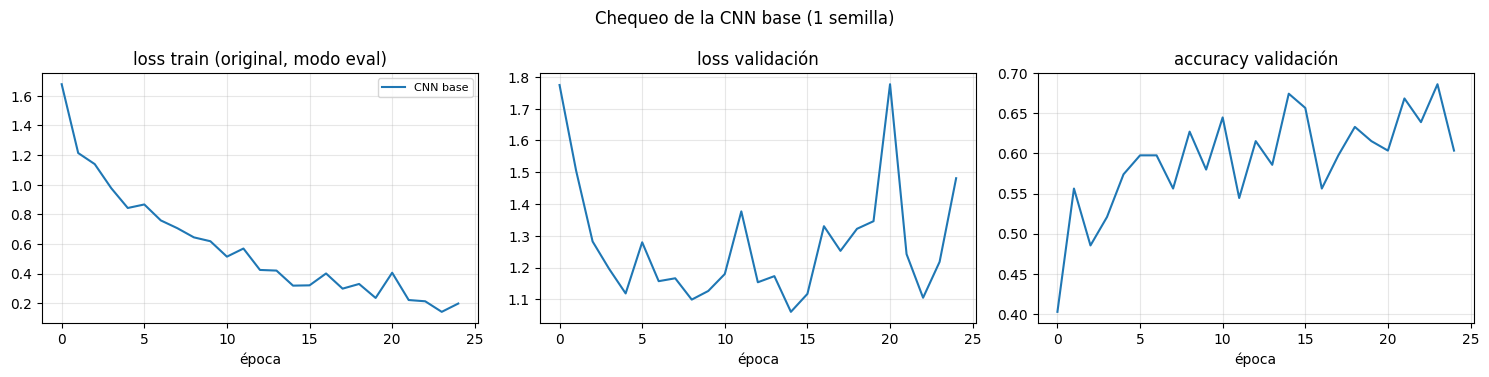

In [11]:
def plot_curves(hists, title):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for name, h in hists.items():
        ax[0].plot(h["train_loss"], label=name); ax[1].plot(h["val_loss"], label=name); ax[2].plot(h["val_acc"], label=name)
    for a, t in zip(ax, ["loss train (original, modo eval)", "loss validación", "accuracy validación"]): a.set_title(t); a.set_xlabel("época"); a.grid(alpha=.3)
    ax[0].legend(fontsize=8); fig.suptitle(title); plt.tight_layout(); plt.show()
t0 = time.time(); _, h = fit(BASE, 0)
print(f"mejor época {h['best_epoch']} | val_acc {h['val_acc'][h['best_epoch']-1]:.3f} | train_acc {h['train_acc'][h['best_epoch']-1]:.3f} | {np.mean(h['epoch_time']):.2f} s/época | total {time.time()-t0:.0f}s")
plot_curves({"CNN base": h}, "Chequeo de la CNN base (1 semilla)")

## 5. De la MLP a la CNN
Misma resolución, mismo split, mismo criterio de parada, 3 semillas. Además de val_acc se mide:
- **Parámetros y tiempo por época.**
- **Robustez a traslaciones**: se evalúa el modelo ya entrenado sobre validación con imágenes **trasladadas** al azar hasta ±`SHIFT` px (la convolución es equivariante a traslaciones y con pooling aproximadamente invariante; la MLP no tiene esa propiedad).

,modelo,params,val_acc,std,train_acc,brecha,mejor_epoca,t_epoca_s,val_acc_trasladada,caida_por_traslacion
0,MLP 32px,1640201,0.4951,0.0388,0.7378,0.2427,5.0000,0.0334,0.4346,0.0605
1,MLP 64px,6358793,0.5247,0.0433,0.7042,0.1796,6.6667,0.0607,0.4372,0.0874
2,CNN 32px,156057,0.6331,0.0084,0.8221,0.1890,8.0000,0.0721,0.5602,0.0730
3,CNN 64px,549273,0.6410,0.0074,0.8043,0.1633,12.0000,0.0790,0.5779,0.0631


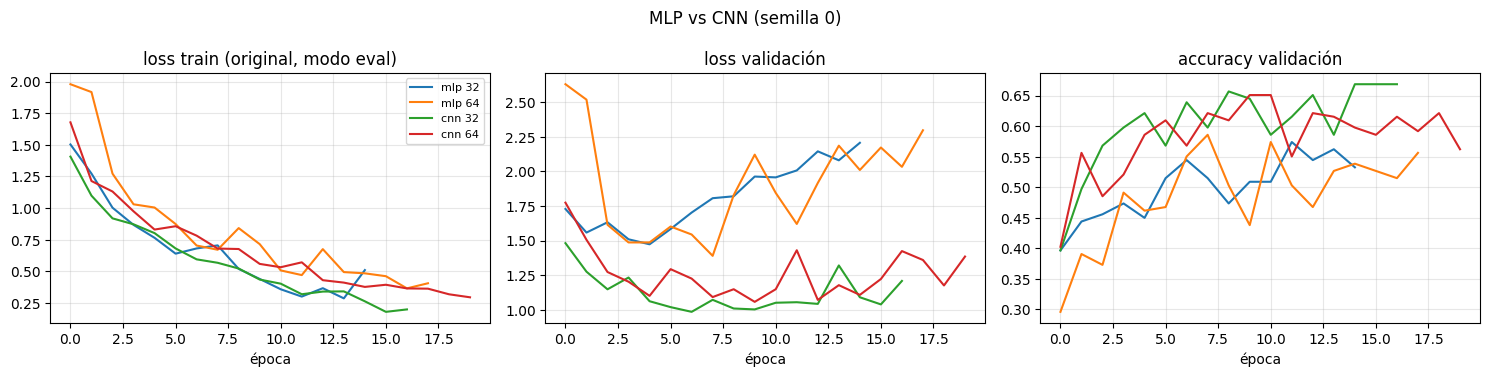

Referencia: azar = 0.111 | error estándar binomial de un accuracy ~0.5 con 169 imágenes de val = 0.038


In [12]:
SHIFT = {32: 4, 64: 8}
rows, store = [], {}
for model_name, size in [("mlp", 32), ("mlp", 64), ("cnn", 32), ("cnn", 64)]:
    cfg = {**BASE, "model": model_name, "size": size}
    r, ms, hs = run(cfg)
    clean = [evaluate(m, idx_va, size)[1] for m in ms]; shifted = [np.mean([evaluate(m, idx_va, size, shift=SHIFT[size])[1] for _ in range(3)]) for m in ms]
    rows.append(dict(modelo=f"{model_name.upper()} {size}px", params=r["params"], val_acc=r["val_acc"], std=r["val_acc_std"], train_acc=r["train_acc"],
                     brecha=r["brecha"], mejor_epoca=r["best_epoch"], t_epoca_s=r["t_epoca_s"],
                     val_acc_trasladada=np.mean(shifted), caida_por_traslacion=np.mean(clean) - np.mean(shifted)))
    store[f"{model_name} {size}"] = hs[0]
display(pd.DataFrame(rows).round(4))
plot_curves(store, "MLP vs CNN (semilla 0)")
print(f"Referencia: azar = {1/NUM_CLASSES:.3f} | error estándar binomial de un accuracy ~0.5 con {len(idx_va)} imágenes de val = {np.sqrt(.25/len(idx_va)):.3f}")

### ✏️ TU ANÁLISIS 1 - De la MLP a la CNN
1. Compará MLP y CNN en **parámetros, val_acc (± desvío), brecha train-val, tiempo por época y época de convergencia**. ¿La diferencia de val_acc supera el ruido entre semillas y el error estándar de la validación?
2. ¿Por qué la MLP necesita tantos más parámetros? Calculá a mano cuántos parámetros tiene la primera capa de la MLP a 32 y a 64 px y explicá qué pasaría a 224 px. ¿Qué propiedades de la convolución (pesos compartidos, conectividad local) cambian ese número?
3. Mirá la **caída por traslación**: ¿cuál de los dos modelos se degrada menos y por qué? ¿Es coherente con la teoría de equivarianza/invarianza, o el ruido no permite concluir?
4. ¿Qué rol cumple la normalización de entrada acá (mencionen cómo se calculó) y qué esperarían si no se hiciera?

1. La CNN gana por amplio margen usando una fracción de los parámetros:   Parámetros: a 32 px la CNN usa 156.057 frente a 1.640.201 de la MLP (unas 10,5 veces menos), y a 64 px usa 549.273 frente a 6.358.793 (11,6 veces menos).   Accuracy en validación (val_acc): a 32 px la CNN llega a 0.6331 ± 0.0084 contra 0.4951 ± 0.0388 de la MLP (+13,8 puntos), y a 64 px alcanza 0.6410 ± 0.0074 contra 0.5247 ± 0.0433 (+11,6 puntos). Esta diferencia de más de 11–13 puntos supera cómodamente tanto el desvío entre semillas (que en la CNN es bajísimo, menor a 0.009, y en la MLP ronda 0.04) como el error estándar binomial de la validación (±0.038 para 169 imágenes).   Brecha, tiempos y convergencia: a 64 px la CNN tiene una brecha train - val algo menor (0.1633 vs. 0.1796) y a 32 px bastante más baja (0.1890 vs. 0.2427). En los gráficos se ve que ambas MLP tocan su mejor época muy rápido (5.0 y 6.7) y enseguida empiezan a sobreajustar (la val_loss se dispara arriba de 2.0), mientras que las CNN siguen aprendiendo de forma más estable hasta las épocas 8.0 y 12.0. En GPU los tiempos por época son muy bajos en ambos casos (0.033–0.061 s en MLP vs. 0.072–0.079 s en CNN).
  2. Porque la MLP aplana toda la imagen en un vector largo y conecta cada píxel individual con cada neurona de la primera capa oculta (512 unidades), sin aprovechar qué píxeles son vecinos. Haciendo la cuenta a mano para esa primera capa Linear:A 32 px: (3 * 32 * 32) * 512 + 512 = 3.072 * 512 + 512 = 1.573.376 parámetros.A 64 px: (3 * 64 * 64) * 512 + 512 = 12.288 * 512 + 512 = 6.291.968 parámetros.A 224 px: (3 * 224 * 224) * 512 + 512 = 150.528 * 512 + 512 = 77.070.848 parámetros (más de 77 millones solo en la primera capa, imposible de entrenar con 506 fotos sin memorizar todo).La convolución evita esa explosión por dos propiedades: conectividad local (cada filtro mira solo una ventanita de 3x3 píxeles en vez de toda la imagen) y pesos compartidos (el mismo filtro recorre toda la imagen, así que la cantidad de parámetros de las capas convolucionales no crece cuando aumenta la resolución).
  3. A 64 px (traslaciones de hasta ±8 px), la CNN se degrada menos que la MLP: pierde 0.0631 puntos (0.6410 a 0.5779, conservando el 90% de su rendimiento), mientras que la MLP cae 0.0874 (0.5247 a 0.4372, perdiendo casi el 17% relativo). A 32 px (±4 px) las caídas absolutas son parecidas (0.0730 vs. 0.0605), en parte porque la MLP ya arranca muy abajo (0.4951).   Esto es coherente con la teoría: las convoluciones son equivariantes a traslaciones (si la lesión se desplaza unos píxeles, su activación en el mapa también se mueve) y MaxPool2d(2) aporta invariancia local aproximada (corrimientos chicos de 1 px no cambian el máximo de la ventana). De todos modos, la invarianza no es perfecta porque el pooling con stride=2 sigue siendo sensible a desplazamientos impares, torch.roll envuelve los bordes de la imagen y el tamaño chico de val (169 fotos) mete algo de ruido.
  4. La normalización resta la media y divide por el desvío de cada canal RGB calculados únicamente sobre train (mean = [0.743, 0.572, 0.565] y std = [0.162, 0.164, 0.186] a 64 px), dejando las entradas centradas cerca de 0 y con escala pareja entre canales. Si no se hiciera, los valores quedarían en [0, 1] con un sesgo positivo fuerte (sobre todo en el canal rojo, ~0.74), lo que desbalancea los gradientes iniciales, hace más lenta la convergencia de Adam y vuelve a la MLP (que no tiene BatchNorm) mucho más vulnerable a cambios de iluminación entre fotos.

## 6. Decisiones de arquitectura convolucional
Se parte de la CNN base y se cambia **un factor a la vez** (3 semillas cada uno): profundidad, tamaño del kernel, cantidad de filtros y resolución de entrada. Se reporta además el **campo receptivo** teórico y los parámetros (que incluyen la capa `Linear` de la cabeza, cuyo tamaño depende de la resolución y la profundidad).

,variante,campo_receptivo,params,val_acc,val_acc_std,train_acc,brecha,best_epoch,t_epoca_s,t_total_s
0,"base (3 bloques, k=3, 16 filtros, 64px)",18,549273,0.6174,0.0279,0.7701,0.1527,10.3333,0.0750,1.5299
1,2 bloques,8,1055001,0.5858,0.0317,0.7708,0.1850,10.0000,0.0678,1.3601
2,4 bloques,38,361113,0.6430,0.0275,0.8742,0.2312,18.3333,0.0867,2.4569
3,kernel 5,32,591001,0.5858,0.0383,0.7806,0.1948,14.0000,0.0845,2.0292
4,kernel 7,46,653593,0.5976,0.0211,0.7325,0.1349,16.3333,0.1096,2.8855
5,8 filtros,18,269521,0.6213,0.0377,0.8228,0.2015,9.6667,0.0720,1.4194
6,32 filtros,18,1143337,0.6154,0.0509,0.7866,0.1712,14.6667,0.1126,2.7781
7,32 px,18,156057,0.6331,0.0084,0.8129,0.1798,8.6667,0.0636,1.1855
8,96 px,18,1204633,0.6016,0.0101,0.7312,0.1296,13.0000,0.1193,2.7513


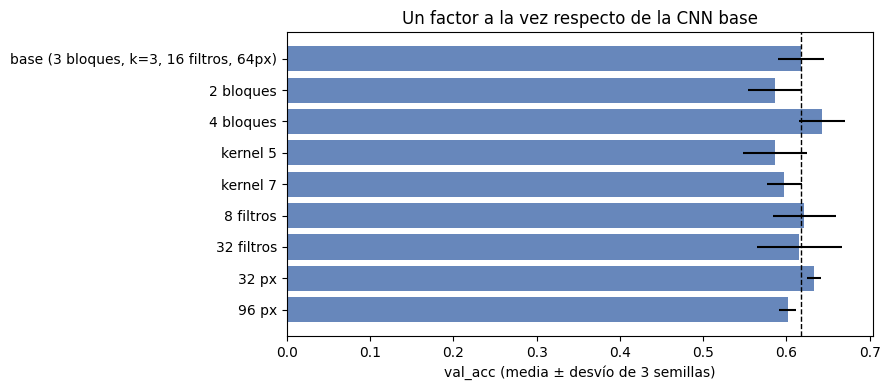

In [13]:
ARCH_VARIANTS = {
    "base (3 bloques, k=3, 16 filtros, 64px)": {},
    "2 bloques": dict(n_blocks=2), "4 bloques": dict(n_blocks=4),
    "kernel 5": dict(kernel=5), "kernel 7": dict(kernel=7),
    "8 filtros": dict(filters=8), "32 filtros": dict(filters=32),
    "32 px": dict(size=32), "96 px": dict(size=96),
}
rows, arch_cfgs, arch_hist = [], {}, {}
for name, delta in ARCH_VARIANTS.items():
    cfg = {**BASE, **delta}; r, ms, hs = run(cfg)
    rows.append(dict(variante=name, campo_receptivo=rf_full(cfg["n_blocks"], cfg["kernel"]), **r)); arch_cfgs[name] = cfg; arch_hist[name] = hs[0]
tab_arch = pd.DataFrame(rows)
display(tab_arch[["variante", "campo_receptivo", "params", "val_acc", "val_acc_std", "train_acc", "brecha", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tab_arch["variante"], tab_arch["val_acc"], xerr=tab_arch["val_acc_std"], color="#4c72b0", alpha=.85); ax.invert_yaxis()
ax.axvline(tab_arch["val_acc"].iloc[0], color="k", ls="--", lw=1); ax.set_xlabel("val_acc (media ± desvío de 3 semillas)"); ax.set_title("Un factor a la vez respecto de la CNN base"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 2 - Arquitectura convolucional
1. ¿Qué factores cambian la val_acc **más allá del ruido entre semillas** (desvío de la tabla) y cuáles no? Sean explícitos sobre qué diferencias son pequeñas respecto del ruido.
2. **Profundidad y kernel:** relacionen el campo receptivo con el tamaño de la imagen y con lo que se quiere detectar en una lesión (bordes, texturas, asimetría global). ¿Qué esperaban de agregar bloques o agrandar el kernel y qué se observó? Comparen costo (parámetros y tiempo) vs. ganancia.
3. **Resolución de entrada (32/64/96):** ¿cómo cambia la cantidad de parámetros de la capa `Linear` de la cabeza y por qué? ¿Qué se gana (detalle disponible) y qué se pierde (cómputo, campo receptivo relativo a la imagen)? Con tan pocas imágenes por clase, ¿qué límite tiene este experimento?
4. ¿Qué no se puede concluir con un diseño de "un factor a la vez" y 3 semillas?

1. Mirando la tabla y el gráfico de barras con los desvíos, lo primero que salta a la vista es que el ruido entre semillas (val_acc_std, que va de 0.0084 hasta 0.0509) es grande en comparación con las diferencias entre variantes: de hecho, las barras de error de casi todas las configuraciones tocan o cruzan la línea de la base (0.6174 ± 0.0279). Aun así, se distinguen bien los cambios que son puro ruido de los que marcan una tendencia real:
  - Diferencias dentro del ruido (sin efecto real): cambiar la cantidad de filtros (8 filtros da 0.6213 ± 0.0377 y 32 filtros da 0.6154 ± 0.0509) mueve la val_acc apenas +0.39 y -0.20 puntos respecto de la base. Esos cambios son totalmente despreciables frente a desvíos de casi 4 o 5 puntos.
-  Diferencias que superan o empatan el desvío de la base (~1 sigma): subir a 4 bloques mejora la val_acc a 0.6430 ± 0.0275 (+2.56 puntos) y bajar la resolución a 32 px llega a 0.6331 ± 0.0084 (+1.57 puntos, con muy poca variación entre semillas). Por el lado negativo, 2 bloques (0.5858 ± 0.0317) y kernel 5 (0.5858 ± 0.0383) caen 3.16 puntos por debajo de la base, seguidos por kernel 7 (0.5976 ± 0.0211, -1.98 puntos) y 96 px (0.6016 ± 0.0101, -1.58 puntos).

2. En lesiones de piel no alcanza con mirar una textura muy chiquita: para distinguir clases hace falta captar bordes, distribución de pigmento y la forma o asimetría global de la lesión.

- Profundidad (cantidad de bloques): con 2 bloques el campo receptivo es de apenas 8 px sobre una imagen de 64 px, demasiado chico para ver la lesión entera; por eso cae la val_acc (0.5858) y encima se duplican los parámetros (1.055.001) porque el mapa llega muy grande (16x16) a la capa Linear. Esperaba que 4 bloques mejorara al darle más contexto espacial, y se cumplió: lleva el campo receptivo a 38 px (casi el 60% del ancho de la imagen) apilando filtros chicos de 3x3, logra la mejor val_acc (0.6430) y encima reduce los parámetros a 361.113 (un 34% menos que la base, porque el mapa final queda de 4x4), con un costo de tiempo mínimo (0.0867 s frente a 0.0750 s por época).

- Tamaño del kernel: también esperaba que agrandar el kernel (kernel 5 con campo receptivo de 32 px, o kernel 7 con 46 px) ayudara por cubrir más área, pero pasó lo contrario: ambos empeoraron (0.5858 y 0.5976), sumaron más parámetros (591.001 y 653.593) y volvieron más lento el entrenamiento (0.1096 s/época en kernel 7). Con tan pocas imágenes de entrenamiento, los filtros grandes tienen demasiados pesos libres y terminan sobreajustando patrones locales en vez de construir jerarquías progresivas como hacen varios bloques de 3x3.

3. Como la CNN base aplica siempre 3 poolings de 2x2, el lado del mapa que entra al Flatten es size / 8 (4x4 en 32 px, 8x8 en 64 px y 12x12 en 96 px). Por eso los parámetros de la primera capa Linear crecen cuadráticamente con el lado de la imagen: pasan de unos 131 mil en 32 px (156.057 totales) a 524 mil en 64 px (549.273 totales) y saltan a casi 1,18 millones en 96 px (1.204.633 totales).
Con mayor resolución (96 px) se gana detalle fino de bordes y texturas, pero se pierde cobertura espacial relativa (el campo receptivo fijo de 18 px cubre más de la mitad de una imagen de 32 px, pero menos de un quinto de una de 96 px), casi se duplica el tiempo por época respecto de 32 px (0.1193 s vs 0.0636 s) y se infla tanto la capa densa que la red memoriza más rápido (val_acc baja a 0.6016, mientras 32 px logra 0.6331).
El límite de este experimento es el tamaño del dataset: con apenas 38 a 60 imágenes por clase en train, la red no tiene suficientes ejemplos variados para aprovechar la mayor definición de 96 px sin sobreajustar esa Linear de más de un millón de parámetros.

4. Al probar un factor a la vez, no puedo detectar interacciones entre decisiones: por ejemplo, tal vez 96 px rendiría mucho mejor si lo combináramos con 4 o 5 bloques (para mantener un campo receptivo proporcional y achicar el mapa antes de la Linear), o el ranking de arquitecturas podría cambiar al sumar data augmentation. Además, con solo 3 semillas y 169 imágenes en validación, la incertidumbre estadística es alta y cualquier diferencia menor a 2.5 - 3 puntos queda dentro del ruido, por lo que no alcanza para asegurar que una variante sea definitivamente mejor que otra.


## 7. Data augmentation
Con ~60 imágenes por clase en train, el overfitting es esperable. Se comparan cuatro niveles de augmentation (los de la sección 3) con la CNN base y 3 semillas. En cada caso, **train queda con las imágenes originales más `AUG_COPIES` copias aumentadas de cada una**; val y test no se tocan.

,augmentation,n_train,val_acc,val_acc_std,train_acc,brecha,val_loss,best_epoch,t_epoca_s,t_total_s
0,ninguna,506,0.6351,0.0266,0.8221,0.1870,0.9967,12.3333,0.0754,1.6808
1,flips,1518,0.6154,0.0097,0.7299,0.1145,1.0340,5.0000,0.2224,3.3429
2,flips+rot90,1518,0.6627,0.0193,0.8518,0.1891,1.0289,11.3333,0.2265,4.8446
3,flips+rot90+color,1518,0.6055,0.0195,0.7563,0.1507,1.0475,7.3333,0.2212,3.8453


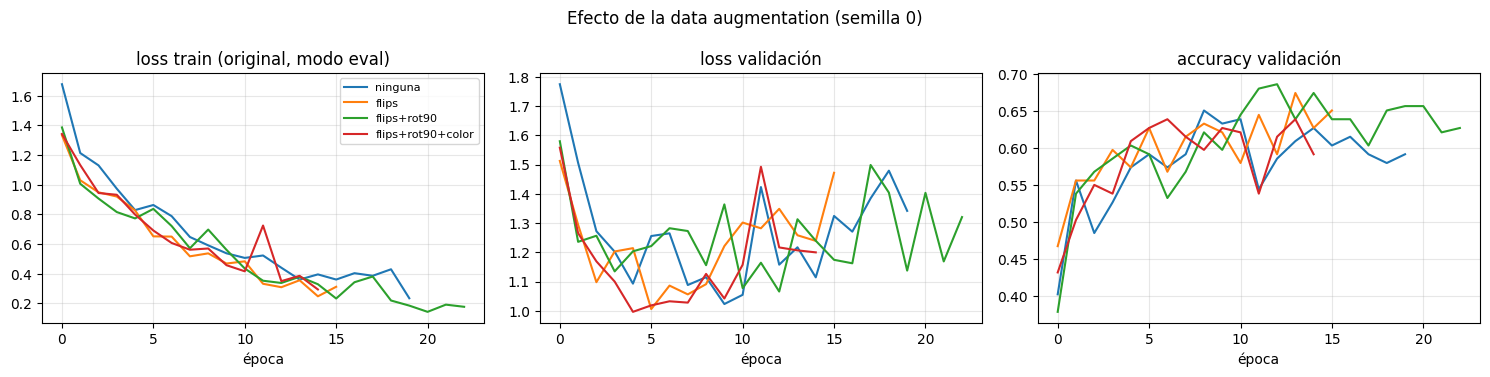

In [14]:
rows, aug_hist = [], {}
for name in AUGS:
    cfg = {**BASE, "aug": name}; r, ms, hs = run(cfg)
    rows.append(dict(augmentation=name, n_train=len(train_set(64, name)[0]), **r)); aug_hist[name] = hs[0]
tab_aug = pd.DataFrame(rows)
display(tab_aug[["augmentation", "n_train", "val_acc", "val_acc_std", "train_acc", "brecha", "val_loss", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
plot_curves(aug_hist, "Efecto de la data augmentation (semilla 0)")

### ✏️ TU ANÁLISIS 3 - Overfitting y augmentation
1. Demostrá el overfitting de la CNN sin augmentation **con números**: brecha train-val, época donde la `val_loss` empieza a subir.
2. ¿Qué cambia con cada nivel de augmentation sobre la **brecha**, la `val_loss`, la `val_acc`, la **época de convergencia** y el **tiempo total**? ¿Por qué cada época cuesta más con augmentation? ¿Cuál de las mejoras supera el ruido entre semillas?
3. Discutan desde el dominio (dermatología) qué transformaciones tienen sentido y cuáles podrían **destruir información** (por ejemplo, el color o la escala). ¿Qué otras augmentations probarían?
4. ¿Por qué es importante que la augmentation se haga **después** del split y **solo en train**? ¿Qué pasaría con las métricas si se aumentara antes de dividir?
5. Compará con lo que vieron en el TP3: ¿qué diferencia hay entre regularizar con dropout/L2 (restricciones sobre los pesos) y con augmentation (más datos sintéticos)?

1. El overfitting se ve claro tanto en la tabla como en las curvas: en el promedio de 3 semillas, la red llega a train_acc = 0.8221 mientras que val_acc queda en 0.6351 ± 0.0266, dejando una brecha de 0.1870 (casi 19 puntos de diferencia; en el chequeo de una semilla de la sección 4.2 llegó incluso a 0.893 vs 0.675, una brecha de 21.8 puntos). Mirando la curva de la semilla 0 (línea azul), train_loss baja de forma pareja desde 1.68 hasta 0.23, mientras que val_loss toca su mínimo alrededor de la época 9 (~1.02) y a partir de ahí empieza a subir con saltos hasta 1.35 - 1.45 (y en el chequeo previo de la sección 4.2 trepó hasta 1.78 después de la época 14). Es decir, sigue memorizando las 506 fotos de entrenamiento sin mejorar en validación.

2. Comparando cada nivel contra "ninguna":
  - flips: achica la brecha a 0.1145 porque frena antes (best_epoch = 5.0, con train_acc = 0.7299), pero empeora la val_loss (1.0340 vs 0.9967) y baja la val_acc a 0.6154 ± 0.0097. No alcanza por sí solo.
  - flips+rot90: es la única que mejora la generalización. Mantiene una brecha parecida (0.1891) porque también sube train_acc (0.8518), converge en best_epoch = 11.33 (similar a 12.33 de la base), deja val_loss = 1.0289 y lleva la val_acc a 0.6627 ± 0.0193 (+2.76 puntos sobre ninguna, con picos cercanos a 0.69 en la curva de validación).   
  - flips+rot90+color: baja la brecha a 0.1507 porque le cuesta ajustar (train_acc = 0.7563), corta más temprano (best_epoch = 7.33), da la peor val_loss (1.0475) y cae a val_acc = 0.6055 ± 0.0195 (-2.96 puntos respecto de ninguna).
  - Tiempo por época y total: como AUG_COPIES = 2 triplica el set de entrenamiento de 506 a 1.518 imágenes, cada época procesa el triple de batches; por eso el tiempo por época se triplica (0.0754 s pasa a ~0.221 - 0.227 s) y el tiempo total sube de 1.68 s a 3.34 - 4.84 s.
  - Ruido entre semillas: la única mejora que supera el desvío entre semillas de la base (0.0266) es flips+rot90 (+0.0276 puntos), aunque sigue estando dentro del error estándar binomial del conjunto de validación (±0.038).

  3. Desde el punto de vista dermatológico, una lesión en la piel no tiene una orientación fija ("arriba" o "abajo"), así que flips y rotaciones de 90° tienen todo el sentido: una lesión rotada sigue perteneciendo exactamente a la misma clase. En cambio, tocar el color, brillo o contraste (color) destruye información diagnóstica clave —como los tonos de pigmentación melánica (marrón claro vs negro), el velo azul-blanquecino del melanoma o el enrojecimiento/tono violáceo de las lesiones vasculares e inflamatorias—, lo que explica que flips+rot90+color haya caído a 0.6055. Tampoco convendrían recortes muy agresivos o cambios fuertes de escala, porque el tamaño de la lesión (criterio de diámetro del ABCDE clínico) y la relación entre borde y centro importan. Como alternativas, probaría rotaciones continuas suaves (por ejemplo ±15° o ±30° con relleno reflejado para no meter bordes negros), traslaciones chicas (±5-10%) y algo de Cutout / borrado aleatorio moderado para que el modelo no dependa de pelos o marcas aisladas.

  4. Es fundamental hacer la augmentation después del split y solo sobre train para que val y test sigan siendo imágenes reales nunca vistas. Si aumentara antes de dividir, versiones apenas rotadas o espejadas de una misma lesión caerían tanto en train como en val o test (data leakage). El modelo terminaría evaluándose sobre copias casi idénticas de fotos que ya memorizó al entrenar, inflando falsamente la val_acc y la test_acc sin reflejar su capacidad real ante pacientes nuevos.

  5. En el TP3, regularizar con Dropout y penalización L2 actuaba sobre los pesos y activaciones del modelo, restringiendo su capacidad efectiva (penalizando pesos grandes o apagando neuronas al azar para evitar que memoricen ruido), pero siempre con los mismos datos de entrada. Con data augmentation, en cambio, la regularización actúa en el espacio de entrada: no limito los pesos de la red, sino que le incorporo invariancias reales del problema (simetría ante rotaciones y reflexiones) y multiplico la variedad del entrenamiento de 506 a 1.518 ejemplos, obligando a los filtros a aprender rasgos que no dependan de la orientación de la foto.

## 8. Elección del modelo final y evaluación en TEST (una sola vez)
Se arma la configuración final tomando, entre las variantes de arquitectura, la de **mejor val_acc media** y, entre las de augmentation, la de **mejor val_acc media** (ambas ya medidas arriba). Se puede forzar otra decisión con `FINAL_OVERRIDE` (justificándola en el análisis). Es una decisión *greedy* de un factor a la vez: no se garantiza que la combinación sea mejor que cada parte.

Luego se entrenan la config final y la MLP de referencia (64 px) con las semillas `SEEDS_FINAL` y se evalúan en test **una única vez**. No se vuelve a tocar nada después de ver estos números.

In [15]:
best_arch = tab_arch.sort_values(["val_acc", "params"], ascending=[False, True]).iloc[0]["variante"]
best_aug  = tab_aug.sort_values("val_acc", ascending=False).iloc[0]["augmentation"]
FINAL_CFG = {**arch_cfgs[best_arch], "aug": best_aug}
FINAL_OVERRIDE = None          # por ejemplo: dict(n_blocks=4, aug="flips+rot90")
if FINAL_OVERRIDE: FINAL_CFG = {**FINAL_CFG, **FINAL_OVERRIDE}
print("Mejor arquitectura (val):", best_arch, "| mejor augmentation (val):", best_aug)
print("Config final:", FINAL_CFG)
rf_, ms_, hs_ = run(FINAL_CFG)
print(f"Config final en validación: val_acc {rf_['val_acc']:.3f} ± {rf_['val_acc_std']:.3f} | brecha {rf_['brecha']:.3f} | mejor época {rf_['best_epoch']:.1f} | {rf_['t_total_s']:.0f}s por entrenamiento")

Mejor arquitectura (val): 4 bloques | mejor augmentation (val): flips+rot90
Config final: {'model': 'cnn', 'size': 64, 'n_blocks': 4, 'filters': 16, 'kernel': 3, 'dropout': 0.2, 'lr': 0.003, 'aug': 'flips+rot90'}
Config final en validación: val_acc 0.651 ± 0.029 | brecha 0.161 | mejor época 9.3 | 5s por entrenamiento


,modelo,params,test_acc,test_acc_std,test_f1_macro,f1_std,tiempo_entrenamiento_s
0,CNN final,361113,0.6722,0.0312,0.6616,0.0432,5.3863
1,MLP 64px,6358793,0.5041,0.0534,0.4872,0.0572,1.0168


Error estándar binomial del test (169 imágenes): ±0.036 | azar: 0.111
                            precision    recall  f1-score   support

         Actinic keratosis       0.57      0.60      0.59        20
         Atopic Dermatitis       0.71      0.94      0.81        16
          Benign keratosis       1.00      0.90      0.95        20
            Dermatofibroma       0.60      0.75      0.67        20
         Melanocytic nevus       0.85      0.55      0.67        20
                  Melanoma       0.57      0.60      0.59        20
   Squamous cell carcinoma       0.59      0.65      0.62        20
Tinea Ringworm Candidiasis       0.70      0.54      0.61        13
           Vascular lesion       1.00      0.90      0.95        20

                  accuracy                           0.72       169
                 macro avg       0.73      0.71      0.72       169
              weighted avg       0.73      0.72      0.72       169



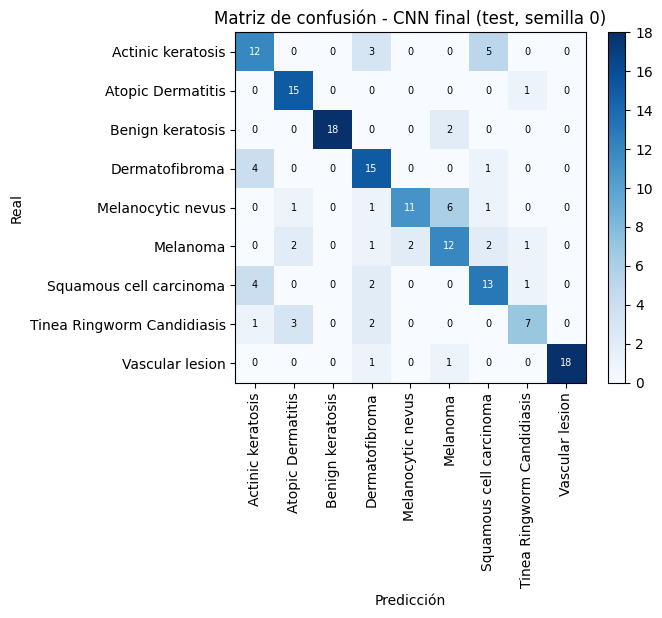

In [16]:
# ---- EVALUACIÓN EN TEST: se ejecuta una sola vez ----
final_rows, final_models, final_preds = [], {}, {}
for name, cfg in [("CNN final", FINAL_CFG), ("MLP 64px", {**BASE, "model": "mlp", "size": 64})]:
    accs, f1s, times = [], [], []
    for s in SEEDS_FINAL:
        m, h = fit(cfg, s); _, a, p = evaluate(m, idx_te, cfg["size"])
        accs.append(a); f1s.append(f1_score(labels[idx_te], p, average="macro")); times.append(sum(h["epoch_time"]))
        if s == SEEDS_FINAL[0]: final_models[name], final_preds[name] = m, p
    final_rows.append(dict(modelo=name, params=h["n_params"], test_acc=np.mean(accs), test_acc_std=np.std(accs), test_f1_macro=np.mean(f1s), f1_std=np.std(f1s), tiempo_entrenamiento_s=np.mean(times)))
final = pd.DataFrame(final_rows); display(final.round(4))
se = np.sqrt(final.loc[0, "test_acc"] * (1 - final.loc[0, "test_acc"]) / len(idx_te))
print(f"Error estándar binomial del test ({len(idx_te)} imágenes): ±{se:.3f} | azar: {1/NUM_CLASSES:.3f}")
p = final_preds["CNN final"]
print(classification_report(labels[idx_te], p, target_names=class_names, zero_division=0))
cm = confusion_matrix(labels[idx_te], p)
plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90); plt.yticks(range(NUM_CLASSES), class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES): plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title(f"Matriz de confusión - CNN final (test, semilla {SEEDS_FINAL[0]})"); plt.tight_layout(); plt.show()

## 9. ¿Qué aprende la red?
Se muestran (sobre imágenes de **validación**, no de test): los filtros de la primera convolución, los **mapas de activación** de la primera y la última capa convolucional para una imagen, y una galería de imágenes **mal clasificadas**.

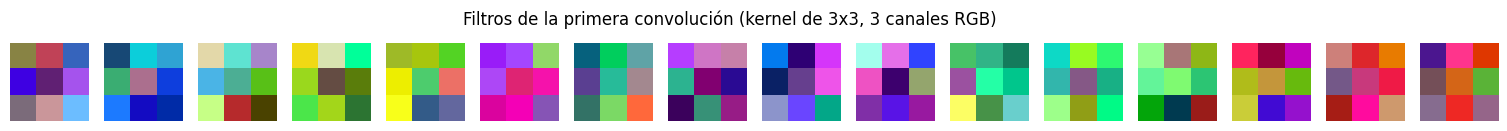

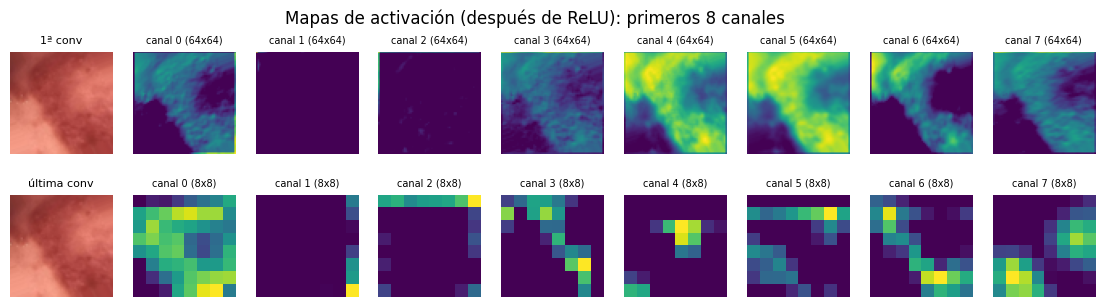

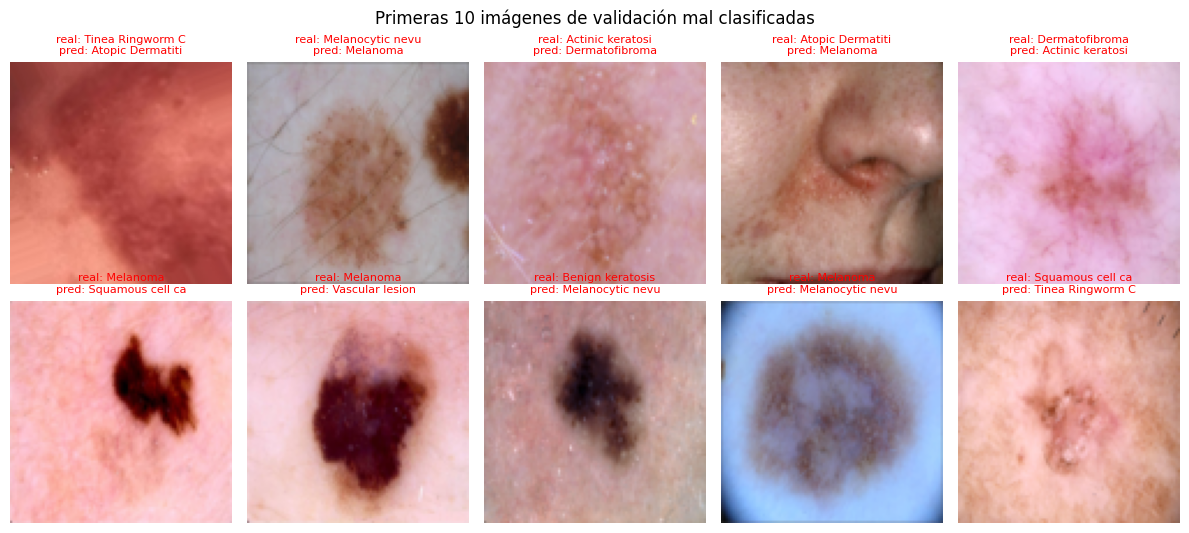

In [17]:
model = final_models["CNN final"].eval(); size = FINAL_CFG["size"]
W = model.features[0].weight.detach().cpu(); n = min(W.shape[0], 16)
fig, ax = plt.subplots(1, n, figsize=(1.2 * n, 1.5))
for i in range(n):
    w = W[i]; w = (w - w.min()) / (w.max() - w.min() + 1e-8); ax[i].imshow(w.permute(1, 2, 0), interpolation="nearest"); ax[i].axis("off")
fig.suptitle("Filtros de la primera convolución (kernel de %dx%d, 3 canales RGB)" % (W.shape[2], W.shape[3])); plt.show()

relu_pos = [i for i, l in enumerate(model.features) if isinstance(l, nn.ReLU)]
xi, yi = get_eval_batch(size, idx_va[:1])
with torch.no_grad(): a_first = model.features[:relu_pos[0] + 1](xi)[0].cpu(); a_last = model.features[:relu_pos[-1] + 1](xi)[0].cpu()
fig, ax = plt.subplots(2, 9, figsize=(14, 3.4))
for r_, (a, nm) in enumerate([(a_first, "1ª conv"), (a_last, "última conv")]):
    ax[r_, 0].imshow(X_U8[size][idx_va[0]].permute(1, 2, 0)); ax[r_, 0].set_title(nm, fontsize=8); ax[r_, 0].axis("off")
    for k in range(8): ax[r_, k + 1].imshow(a[k], cmap="viridis"); ax[r_, k + 1].axis("off"); ax[r_, k + 1].set_title(f"canal {k} ({a.shape[1]}x{a.shape[2]})", fontsize=7)
plt.suptitle("Mapas de activación (después de ReLU): primeros 8 canales"); plt.show()

_, _, pv = evaluate(model, idx_va, size)
bad = [i for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]; pbad = [p_ for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]
fig, ax = plt.subplots(2, 5, figsize=(12, 5.4))
for a, i, pr in zip(ax.flat, bad, pbad):
    a.imshow(X_U8[96][i].permute(1, 2, 0)); a.axis("off"); a.set_title(f"real: {class_names[labels[i]][:16]}\npred: {class_names[pr][:16]}", fontsize=8, color="red")
plt.suptitle("Primeras 10 imágenes de validación mal clasificadas"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 4 - Resultados finales e interpretación
1. **Consistencia val vs. test:** ¿el resultado de test es coherente con la validación? Tengan en cuenta el error estándar binomial del test y que elegimos el mejor entre varias configuraciones sobre validación (sesgo optimista).
2. **CNN vs. MLP en test:** ¿la diferencia supera el ruido entre semillas (± desvío) y el error estándar del test? ¿Se justifica el costo en parámetros/tiempo?
3. **Matriz de confusión y reporte por clase:** ¿qué clases se confunden más y por qué (similitud clínica/visual)? En este problema, ¿es igual de grave confundir cualquier par de clases? ¿Qué métrica (recall de melanoma, F1 macro, otra) les parece más relevante que el accuracy y por qué?
4. **Filtros, mapas de activación y errores:** ¿qué detectan las primeras capas y qué cambia en la última (tamaño espacial, nivel de abstracción)? ¿Qué patrones comunes tienen las imágenes mal clasificadas?
5. **Sesgos y limitaciones:** retomen el EDA (resoluciones y color por clase, duplicados). ¿Qué sesgos del dataset podrían inflar o distorsionar los números? Tamaño del dataset, una sola partición, pocas semillas, validación chica: ¿qué harían con más tiempo?

1. El resultado en test es totalmente coherente con lo que vi en validación. La CNN final (4 bloques + flips+rot90) logra un test_acc = 0.6722 ± 0.0312 en el promedio de 5 semillas (0.72 en la semilla 0), que acompaña muy bien los valores que habían dado 4 bloques (0.6430 ± 0.0275) y flips+rot90 (0.6627 ± 0.0193) por separado en validación. Aunque elegir las mejores opciones mirando validación siempre mete algo de sesgo optimista, al juntarlas no hubo caída en datos nuevos y la diferencia entra dentro del error estándar binomial del test (±0.036 para 169 imágenes), así que la validación fue una buena guía.
2. En test, la CNN final le saca una ventaja enorme a la MLP 64px: llega a 0.6722 ± 0.0312 de accuracy y 0.6616 ± 0.0432 de F1-macro contra 0.5041 ± 0.0534 y 0.4872 ± 0.0572 de la MLP. Esa diferencia de casi +17 puntos supera por lejos tanto el desvío entre semillas de ambos modelos (0.0312 y 0.0534) como el error estándar del test (±0.036). Además, la CNN usa 361.113 parámetros (más de 17 veces menos que los 6.358.793 de la MLP). Si bien tarda más en entrenar (5.39 s frente a 1.02 s en GPU, porque tiene 4 bloques y entrena con el triple de imágenes por la augmentation), 5 segundos sigue siendo despreciable y se justifica completamente por el salto de rendimiento.  
3. Mirando la matriz de confusión y el reporte por clase en test (semilla 0, accuracy 0.72), las clases más fáciles son Benign keratosis y Vascular lesion (F1 = 0.95, 18/20 aciertos cada una) junto con Atopic Dermatitis (F1 = 0.81, 15/16). Las confusiones principales tienen una explicación visual y clínica clara:
- Melanocytic nevus vs. Melanoma: 6 de 20 nevos se predicen como Melanoma (recall = 0.55) y 2 de 20 melanomas como Melanocytic nevus (recall = 0.60), porque ambos son lesiones pigmentadas marrones o negras muy parecidas a simple vista.
- Actinic keratosis vs. Squamous cell carcinoma: 5 de 20 queratosis actínicas se confunden con carcinoma escamoso y 4 de 20 al revés; clínicamente tiene sentido porque la queratosis actínica es justamente la lesión precursora del carcinoma escamoso.
- Tinea Ringworm Candidiasis vs. Atopic Dermatitis: 3 de 13 tiñas se predicen como dermatitis atópica por ser placas rojizas y descamativas en fotos clínicas.

  En este problema no es igual de grave cualquier error: confundir un lunar benigno con melanoma manda al paciente a una biopsia o control, pero clasificar un Melanoma (8/20 falsos negativos) o un Squamous cell carcinoma (7/20 falsos negativos) como benigno retrasa el tratamiento de un cáncer peligroso. Por eso, el recall de las clases malignas (sobre todo de Melanoma) junto con el F1-macro (0.6616 ± 0.0432, que pesa igual a las clases más chicas como Tinea) son métricas mucho más relevantes que el accuracy global.   

4. En los gráficos de interpretabilidad se ve bien cómo procesa la imagen la red:
- Primeras capas vs. última: los 16 filtros de 3x3 de la primera convolución detectan contrastes básicos de color (tonos rosados/rojizos de piel frente a zonas oscuras o azuladas) y bordes simples. En los mapas de activación, la 1ª conv (64x64) conserva la forma exacta de la lesión y la textura fina de la piel (con algunos canales apagados por ReLU, como el 1 y el 2, y otros marcando el cuerpo o el contorno, como el 4, 5 y 6). En la última conv (8x8), en cambio, la resolución espacial se reduce y las activaciones pasan a ser bloques abstractos que localizan zonas puntuales, como el centro de la lesión (canal 4) o arcos del borde (canal 3 y 6).
- Patrones en los errores de validación: en las 10 imágenes mal clasificadas se repiten cuatro problemas claros: (i) artefactos físicos como pelos sobre la piel (Melanocytic nevus -> Melanoma) y viñetas negras circulares del dermatoscopio (Melanoma -> Melanocytic nevus); (ii) fotos clínicas con contexto anatómico complejo, como una nariz en Atopic Dermatitis -> Melanoma; (iii) lesiones rosadas con muy poco contraste respecto de la piel sana (Actinic keratosis -> Dermatofibroma y viceversa); y (iv) parecido visual real, como un melanoma nodular oscuro/violáceo confundido con Vascular lesion o una queratosis oscura confundida con Melanocytic nevus.

5. Retomando el EDA, el principal sesgo del dataset es que mezcla fotos clínicas comunes (Atopic Dermatitis 100% en 294x222, con RGB más oscuro y partes del cuerpo de fondo) con dermatoscopías (Melanoma y Melanocytic nevus mayormente en 1024x768 y con bordes negros), además de tener cuatro clases 100% en 600x450. Eso permite que la red use atajos de origen o resolución (como el suavizado al reescalar o las viñetas) en vez de mirar solo la lesión, inflando los aciertos en clases con formato único como Atopic Dermatitis (recall = 0.94) o Benign keratosis (F1 = 0.95). A eso se suma que había 34 duplicados exactos en los datos crudos, señal de una curación poco prolija.   Como limitaciones del experimento, 506 imágenes de entrenamiento y 169 de test (13 a 20 por clase) dejan un error estándar alto (±0.036), y usar una única partición, pocas semillas (3 y 5) y búsqueda de un factor a la vez limita la certeza estadística. Con más tiempo haría validación cruzada estratificada (k-fold) para aprovechar mejor todos los datos, probaría transfer learning con una red preentrenada (como ResNet o EfficientNet), usaría pesos por clase o Focal Loss para penalizar más los falsos negativos en Melanoma, y aplicaría un preprocesamiento para recortar viñetas y limpiar pelos antes de entrenar.



## Declaración de uso de IA
Completen (obligatorio): ¿usaron herramientas de IA? ¿Cuáles, para qué parte (código, redacción del análisis, ideas) y qué modificaron o verificaron por su cuenta? Si no usaron, aclaren que no.

> Sí, utilicé Gemini como herramienta de apoyo. Como la mayor parte del código ya venía dada en el notebook de la cátedra, en esa parte solo lo usé para resolver cómo cargar y ubicar la carpeta de imágenes (data/Split_smol) en el entorno de Google Colab debido a que no podia descargar la carpeta. Además, me sirvió como espacio de intercambio para interpretar algunos gráficos como las curvas de entrenamiento, los mapas de activación y los casos mal clasificados; y para ayudar a ordenar y pulir la redacción de algunas respuestas. Por mi cuenta ejecuté todo el notebook en GPU, verifiqué que cada número, cálculo y conclusión coincidiera exactamente con los outputs reales de mi corrida y redacté y modifiqué los textos finales para que reflejaran mis propias observaciones.